# 01-2. 자료 구성과 품질

01(데이터 탐색)의 1~3장. 제공 자료의 파일 구성과 관측망의 공간 구조를 확인하고, 결측·이상값·센서 고착·자료 간 시각 정렬을 점검한다.
점검 결과를 반영한 분석용 자료를 저장해 01-3 ~ 01-7에서 쓴다 (3-6).

01 구성: 01-1 이론(0장) · **01-2 자료 구성·품질(1~3장)** · 01-3 노면온도·노면상태(4~5장) · 01-4 결빙 기상 조건·검증 지점(6~10장) · 01-5 도로·지형·목표안개(11~12장) · 01-6 이론 검증 Ⅰ(13-1~13-4) · 01-7 이론 검증 Ⅱ·정리(13-5~14장)

| 구분 | 자료 | 간격 | 비고 |
|------|------|------|------|
| 1 | 고속도로 RWIS(도로기상) | 10분 | 노면상태·노면온도 등, 17개소 |
| 1-1 | 목표안개 관측소 | 10분 | 시정만 관측, 2개소 |
| 2 | ASOS(종관기상) | 1시간 | 10개소 |
| 3 | AWS(방재기상) | 10분(1분 평균) | 34개소 |
| 4~5 | 교량·터널 위경도 | - | 고속도로 교량·터널 위치 |
| 6 | 고속도로 중심선 | - | shapefile (EPSG:5179) |
| 7 | 수치 표고 모델 | - | 30m 격자 GeoTIFF |
| 8 | 국토부 도로·교량·터널·하천 경계 | - | zip 안의 shapefile |

- 출력: 분석용 관측 자료 4종, 지점 정보(DEM 표고 포함), DEM 환산 계수 (`data/interim/`)

**목차**

1. 데이터 구성과 파일 점검
2. 관측망과 공간 구조 (DEM 표고 단위 포함)
3. 자료 품질 (결측, 이상값, 센서 고착, 시각 정렬, 분석용 자료 저장)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import glob
import json
import os
import re
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import shapely
from cycler import cycler
from matplotlib import font_manager
from scipy.spatial.distance import cdist

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# 한글 글꼴 (설치된 것 중 먼저 찾은 것)
for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=PALETTE),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
ROUTE_COLORS = {"서해안": PALETTE[0], "호남선": PALETTE[1], "통영-대전중부선": PALETTE[2]}
INK, MUTED = "#0b0b0b", "#898781"
HOLDOUT = list(config.HOLDOUT_STATIONS)
CRS = 5179

## 1. 데이터 구성과 파일 점검

### 1-1. 일별 파일 목록

관측 자료는 하루 하나씩 CSV로 나뉘어 있다. 파일마다 행 수, 컬럼 구성, 파일 이름의 날짜와 내용의 날짜가 일치하는지 확인하며 불러온다.

In [3]:
TIME_COLS = {"rwis": "관측시각 (KST)", "fog": "관측시각 (KST)", "asos": "시간", "aws": "시간(KST)"}
LABELS = {"rwis": "1. RWIS", "fog": "1-1. 목표안개", "asos": "2. ASOS", "aws": "3. AWS"}


def load_observations(source):
    """일별 CSV를 기간 전체로 합치고, 파일별 점검 결과를 함께 돌려준다."""
    files = sorted(glob.glob(str(config.RAW_DIR / config.RAW_FILES[source])))
    frames, info = [], []
    for f in files:
        d = pd.read_csv(f, encoding=config.CSV_ENCODING)
        file_date = "".join(re.search(r"(\d{4})-?(\d{2})-?(\d{2})", Path(f).name).groups())
        content_date = d[TIME_COLS[source]].astype(str).str.replace("-", "").str[:8]
        info.append({"rows": len(d), "header": tuple(d.columns), "date_ok": bool((content_date == file_date).all()),
                     "MB": os.path.getsize(f) / 1e6})
        frames.append(d)
    return pd.concat(frames, ignore_index=True), pd.DataFrame(info)


raw, inventory = {}, []
for source in TIME_COLS:
    raw[source], info = load_observations(source)
    inventory.append({"자료": LABELS[source], "파일 수": len(info), "전체 행": len(raw[source]),
                      "파일당 행(최소)": info["rows"].min(), "파일당 행(최대)": info["rows"].max(),
                      "컬럼 수": len(info["header"].iloc[0]), "컬럼 구성 종류": info["header"].nunique(),
                      "날짜 불일치 파일": int((~info["date_ok"]).sum()), "용량(MB)": round(info["MB"].sum(), 1)})
pd.DataFrame(inventory).set_index("자료")

,파일 수,전체 행,파일당 행(최소),파일당 행(최대),컬럼 수,컬럼 구성 종류,날짜 불일치 파일,용량(MB)
자료,,,,,,,,
1. RWIS,240,587445,2419,2448,24,1,0,99.1
1-1. 목표안개,240,69118,286,288,9,1,0,6.6
2. ASOS,240,57600,240,240,30,1,0,7.0
3. AWS,240,1152144,4752,4896,21,1,0,146.6


- 네 자료 모두 240개 파일(240일)이고, 파일마다 컬럼 구성이 같으며, 파일 이름의 날짜와 내용의 날짜가 모두 일치한다.
- RWIS는 하루 17개소 x 144회 = 2,448행이 최대인데 일부 파일은 그보다 적다(누락 시각, 3장).
- AWS는 하루 33개소(4,752행)인 날과 34개소(4,896행)인 날이 있다. 서전주 지점이 일부 기간에만 있다(3장).

### 1-2. 컬럼 구성과 공통 이름

관측시각 표기와 지점번호 컬럼명이 자료마다 다르므로 공통 이름(`time`, `stn`)으로 맞춘다.

| 자료 | 시각 컬럼 | 형식 | 지점 컬럼 | 결측 표기 |
|------|-----------|------|-----------|-----------|
| RWIS·목표안개 | `관측시각 (KST)` | `202411010000` (정수) | `관측 지점번호` | -999 |
| ASOS | `시간` | `2024-11-01 00:00` | `지점` | 빈칸 |
| AWS | `시간(KST)` | `2024-11-01 00:00:00` | `지점 번호` | -99.x |

In [4]:
rwis, fog, asos, aws = raw["rwis"], raw["fog"], raw["asos"], raw["aws"]
for df in (rwis, fog):
    df["time"] = pd.to_datetime(df["관측시각 (KST)"].astype(str), format="%Y%m%d%H%M")
    df["stn"] = df["관측 지점번호"]
    for c in ["관측 지점명", "고속도로", "관측소 종류"]:
        df[c] = df[c].str.strip()
asos["time"], asos["stn"] = pd.to_datetime(asos["시간"]), asos["지점"]
aws["time"], aws["stn"] = pd.to_datetime(aws["시간(KST)"]), aws["지점 번호"]
for name, df in [("RWIS", rwis), ("목표안개", fog), ("ASOS", asos), ("AWS", aws)]:
    print(f"{name:5s} 컬럼: {', '.join(c for c in df.columns if c not in ['time', 'stn'])}")

RWIS  컬럼: 관측시각 (KST), 관측 지점번호, 관측 지점명, 고속도로, 관측소 종류, 관측소 위도, 관측소 경도, 관측소 고도 (m), 노면상태, 노면온도 (광학), 시정 (m), 습도 (%), 일 누적 강수량 (mm), 적설 (cm), 기온 (C), 1분 풍향 (Degree), 1분 풍속 (m/s), 최대순간풍향 (Degree), 최대순간풍속 (m/s), 해면기압 (hPa), 운고1, 운고2, 운고3, 운량
목표안개  컬럼: 관측시각 (KST), 관측 지점번호, 관측 지점명, 고속도로, 관측소 종류, 관측소 위도, 관측소 경도, 관측소 고도 (m), 시정 (m)
ASOS  컬럼: Unnamed: 0, 시간, 지점, 지점명, 위도, 경도, 기온(°C), 강수량(mm), 풍속(m/s), 풍향(16방위), 습도(%), 증기압(hPa), 이슬점온도(°C), 현지기압(hPa), 해면기압(hPa), 일조(hr), 일사(MJ/m2), 적설(cm), 3시간신적설(cm), 전운량(10분위), 중하층운량(10분위), 운형(운형약어), 최저운고(100m), 시정(10m), 현상번호(국내식), 지면온도(°C), 5cm 지중온도(°C), 10cm 지중온도(°C), 20cm 지중온도(°C), 30cm 지중온도(°C)
AWS   컬럼: 시간(KST), 지점 번호, 지점명, 위도, 경도, 1분 평균 풍향(degree), 1분 평균 풍속(m/s), 최대 순간 풍향(degree), 최대 순간 풍속(m/s), 10분 평균 풍향(degree), 10분 평균 풍속(m/s), 1분 평균 기온(°C), 강수감지(0-무강수), 15분 누적 강수량(mm), 60분 누적 강수량(mm), 12시간 누적 강수량(mm), 일 누적 강수량(mm), 1분 평균 상대습도(%), 1분 평균 현지기압(hPa), 1분 평균 해면기압(hPa), 이슬점온도(°C)


In [5]:
rwis.head(3)

,관측시각 (KST),관측 지점번호,관측 지점명,고속도로,관측소 종류,관측소 위도,관측소 경도,관측소 고도 (m),노면상태,노면온도 (광학),시정 (m),습도 (%),일 누적 강수량 (mm),적설 (cm),기온 (C),1분 풍향 (Degree),1분 풍속 (m/s),최대순간풍향 (Degree),최대순간풍속 (m/s),해면기압 (hPa),운고1,운고2,운고3,운량,time,stn
0,202411010000,12103,군산휴(도),서해안,거점,36.0202,126.7959,33,1,14.6,16550,84.6,0.0,0.0,14.6,313.5,0.0,314.4,0.5,1022,7620,7620,7620,1,2024-11-01 00:00:00,12103
1,202411010010,12103,군산휴(도),서해안,거점,36.0202,126.7959,33,1,14.6,18060,81.9,0.0,0.0,14.6,185.7,0.4,212.9,0.6,1022,7579,7620,7620,1,2024-11-01 00:10:00,12103
2,202411010020,12103,군산휴(도),서해안,거점,36.0202,126.7959,33,1,14.4,18260,79.8,0.0,0.0,14.7,68.7,1.2,74.9,1.5,1022,7280,7620,7620,1,2024-11-01 00:20:00,12103


In [6]:
asos.head(3)

,Unnamed: 0,시간,지점,지점명,위도,경도,기온(°C),강수량(mm),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),이슬점온도(°C),현지기압(hPa),해면기압(hPa),일조(hr),일사(MJ/m2),적설(cm),3시간신적설(cm),전운량(10분위),중하층운량(10분위),운형(운형약어),최저운고(100m),시정(10m),현상번호(국내식),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),time,stn
0,0,2024-11-01 00:00,140,군산,36.0053,126.7614,14.4,NaN,0.5,200.0,78.0,12.8,10.6,1019.9,1023.2,NaN,NaN,NaN,NaN,10.0,2.0,NaN,NaN,2184.0,NaN,13.5,NaN,NaN,NaN,NaN,2024-11-01 00:00:00,140
1,1,2024-11-01 01:00,140,군산,36.0053,126.7614,13.7,NaN,0.3,0.0,83.0,12.9,10.8,1020.0,1023.4,NaN,NaN,NaN,NaN,9.0,7.0,NaN,66.0,2141.0,NaN,13.2,NaN,NaN,NaN,NaN,2024-11-01 01:00:00,140
2,2,2024-11-01 02:00,140,군산,36.0053,126.7614,13.8,NaN,0.7,200.0,79.0,12.4,10.2,1019.8,1023.2,NaN,NaN,NaN,NaN,10.0,9.0,NaN,57.0,2109.0,NaN,13.3,NaN,NaN,NaN,NaN,2024-11-01 02:00:00,140


In [7]:
aws.head(3)

,시간(KST),지점 번호,지점명,위도,경도,1분 평균 풍향(degree),1분 평균 풍속(m/s),최대 순간 풍향(degree),최대 순간 풍속(m/s),10분 평균 풍향(degree),10분 평균 풍속(m/s),1분 평균 기온(°C),강수감지(0-무강수),15분 누적 강수량(mm),60분 누적 강수량(mm),12시간 누적 강수량(mm),일 누적 강수량(mm),1분 평균 상대습도(%),1분 평균 현지기압(hPa),1분 평균 해면기압(hPa),이슬점온도(°C),time,stn
0,2024-11-01 00:00:00,300,말도,35.858,126.3151,77.7,1.7,63.3,4.8,70.6,1.5,18.1,0.0,0.0,0.0,0.0,0.0,77.7,1016.8,1022.0,14.1,2024-11-01 00:00:00,300
1,2024-11-01 00:10:00,300,말도,35.858,126.3151,52.4,2.2,45.1,3.9,62.9,2.3,18.1,0.0,0.0,0.0,0.0,0.0,76.2,1016.9,1022.1,13.8,2024-11-01 00:10:00,300
2,2024-11-01 00:20:00,300,말도,35.858,126.3151,88.4,1.2,47.2,2.4,106.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,76.2,1016.8,1022.0,13.8,2024-11-01 00:20:00,300


## 2. 관측망과 공간 구조

### 2-1. 기간과 지점

In [8]:
for name, df in [("RWIS", rwis), ("목표안개", fog), ("ASOS", asos), ("AWS", aws)]:
    print(f"{name:5s}: {df['time'].min()} ~ {df['time'].max()}, 관측일수 {df['time'].dt.normalize().nunique()}, "
          f"지점 {df['stn'].nunique()}개")

in_period = np.zeros(len(rwis), dtype=bool)
for start, end in config.PERIODS:
    in_period |= rwis["time"].between(start, pd.Timestamp(end) + pd.Timedelta("23:50:00"))
print("RWIS 분석 기간 밖 관측:", (~in_period).sum())

RWIS : 2024-11-01 00:00:00 ~ 2026-02-28 23:50:00, 관측일수 240, 지점 17개
목표안개 : 2024-11-01 00:00:00 ~ 2026-02-28 23:50:00, 관측일수 240, 지점 2개
ASOS : 2024-11-01 00:00:00 ~ 2026-02-28 23:00:00, 관측일수 240, 지점 10개
AWS  : 2024-11-01 00:00:00 ~ 2026-02-28 23:50:00, 관측일수 240, 지점 34개
RWIS 분석 기간 밖 관측: 0


두 겨울(2024-11 ~ 2025-02, 2025-11 ~ 2026-02) 각 120일, 총 240일이다. 10분 간격이면 지점당 34,560개(240일 x 144)가 최대이다.

In [9]:
assert rwis.groupby("stn")[["관측소 위도", "관측소 경도", "관측소 고도 (m)"]].nunique().max().max() == 1  # 위치 고정
rwis_st = (
    rwis.groupby("stn")
    .agg(지점명=("관측 지점명", "first"), 노선=("고속도로", "first"), 종류=("관측소 종류", "first"),
         위도=("관측소 위도", "first"), 경도=("관측소 경도", "first"), 고도=("관측소 고도 (m)", "first"),
         관측수=("time", "size"))
    .reset_index()
)
rwis_st["검증지점"] = rwis_st["stn"].isin(HOLDOUT)
rwis_st

,stn,지점명,노선,종류,위도,경도,고도,관측수,검증지점
0,12103,군산휴(도),서해안,거점,36.0202,126.7959,33,34554,False
1,12209,서김제(도),서해안,기본,35.8347,126.8398,12,34559,False
2,12210,부안고려청자휴(도),서해안,기본,35.6733,126.7345,10,34559,False
3,12211,고인돌휴(도),서해안,기본,35.4643,126.6730,52,34559,False
4,12409,우곡3교(도),서해안,목표(결빙),35.9853,126.8249,13,34546,False
5,12410,부곡교(도),서해안,목표(결빙),35.6433,126.7141,17,34559,True
6,23202,여산휴(도),호남선,기본,36.0476,127.1036,70,34523,False
7,23203,삼례졸음(도),호남선,기본,35.9185,127.0710,25,34559,False
8,23204,정읍휴(도),호남선,기본,35.6002,126.8626,31,34555,False
9,23402,해전(도),호남선,목표(결빙),35.8999,127.0578,13,34559,True


In [10]:
pd.crosstab(rwis_st["노선"], rwis_st["종류"], margins=True, margins_name="합계")

종류,거점,기본,목표(결빙),합계
노선,,,,
서해안,1,3,2,6
통영-대전중부선,1,1,4,6
호남선,0,3,2,5
합계,2,7,8,17


In [11]:
kinds = rwis_st.groupby("종류")["stn"].apply(list)
print({k: len(v) for k, v in kinds.items()})
print("검증 지점의 종류:", rwis_st.loc[rwis_st["검증지점"], ["지점명", "종류"]].values.tolist())

{'거점': 2, '기본': 7, '목표(결빙)': 8}
검증 지점의 종류: [['부곡교(도)', '목표(결빙)'], ['해전(도)', '목표(결빙)'], ['삼봉(도)', '목표(결빙)']]


- RWIS는 17개소이고 노선 이름은 `서해안`, `통영-대전중부선`, `호남선`이다 (config.TARGET_ROUTES와 일치).
- 관측소 종류는 **거점 2, 기본 7, 목표(결빙) 8개소**이다. 검증 지점 3곳(부곡교, 삼봉, 해전)은 모두 목표(결빙) 관측소이다.
- 통영-대전중부선은 6개소 중 4개소가 목표(결빙)이다. 산지 노선이라 결빙 감시 지점을 집중 배치한 것으로 보인다.

In [12]:
def to_points(df, lon="경도", lat="위도"):
    return gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df[lon], df[lat]), crs=4326).to_crs(CRS)


fog_st = fog.groupby("stn").agg(지점명=("관측 지점명", "first"), 노선=("고속도로", "first"),
                                위도=("관측소 위도", "first"), 경도=("관측소 경도", "first"),
                                고도=("관측소 고도 (m)", "first")).reset_index()
asos_st = asos.groupby("stn").agg(지점명=("지점명", "first"), 위도=("위도", "first"), 경도=("경도", "first"),
                                  관측수=("time", "size")).reset_index()
aws_st = aws.groupby("stn").agg(지점명=("지점명", "first"), 위도=("위도", "first"), 경도=("경도", "first"),
                                관측수=("time", "size")).reset_index()
rwis_pt, fog_pt, asos_pt, aws_pt = (to_points(d) for d in (rwis_st, fog_st, asos_st, aws_st))
print("ASOS 지점당 관측수:", asos_st["관측수"].unique(), "(1시간 간격, 240일 x 24)")
fog_st

ASOS 지점당 관측수: [5760] (1시간 간격, 240일 x 24)


,stn,지점명,노선,위도,경도,고도
0,12306,운양교(도),서해안,35.4818,126.6793,30
1,33312,잠두교(도),통영-대전중부선,35.9942,127.6098,212


### 2-2. DEM 표고 단위 확인

표고는 결빙과 직접 관련된 변수(기온감률)이므로 DEM 값을 먼저 확인한다.

In [13]:
dem_path = config.RAW_DIR / config.RAW_FILES["dem"]
with rasterio.open(dem_path) as src:
    print("CRS:", src.crs.to_wkt()[:90], "...")
    print("해상도:", src.res, "크기:", src.shape, "nodata:", src.nodata)
    print("범위:", src.bounds)
    step = 4
    dem_small = src.read(1, out_shape=(src.height // step, src.width // step)).astype(float)
    dem_bounds = src.bounds
    rwis_pt["DEM값"] = [v[0] for v in src.sample(np.c_[rwis_pt.geometry.x, rwis_pt.geometry.y])]
dem_small[dem_small < -1000] = np.nan
print("DEM 값 범위:", np.nanmin(dem_small), "~", np.nanmax(dem_small))

CRS: PROJCS["ITRF_2000_Transverse_Mercator",GEOGCS["ITRF2000",DATUM["International_Terrestrial_ ...
해상도: (29.999999999999993, 30.0) 크기: (5692, 5835) nodata: -3.4028230607370965e+38
범위: BoundingBox(left=862040.7238255, bottom=1700465.1788528003, right=1037090.7238255, top=1871225.1788528003)
DEM 값 범위: 0.0 ~ 0.8850515484809875


DEM은 30m 격자이고 좌표계가 ITRF2000 TM(중부원점 127.5°, 1,000,000 / 2,000,000)으로 EPSG:5179와 같다.
그런데 **DEM 값이 미터가 아니라 0~0.89 범위로 정규화되어 있다.** RWIS 관측소 고도(제공값)와 비교해 환산 계수를 구한다.

환산 계수: DEM값 x 1955.9 = 표고(m), 상관계수 0.998
DEM 최댓값 0.885 → 약 1731m


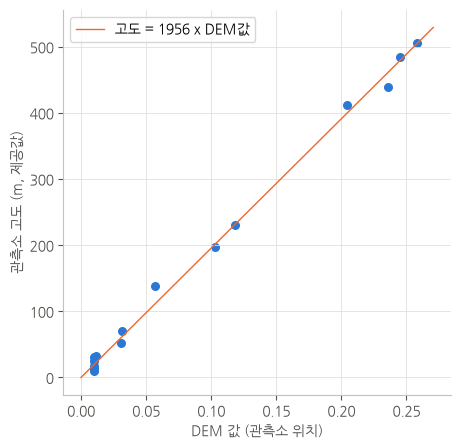

,stn,지점명,고도,DEM값,DEM표고,차이
0,12103,군산휴(도),33,0.0,22.2,-10.8
1,12209,서김제(도),12,0.0,20.2,8.2
2,12210,부안고려청자휴(도),10,0.0,20.2,10.2
3,12211,고인돌휴(도),52,0.0,60.5,8.5
4,12409,우곡3교(도),13,0.0,20.2,7.2
5,12410,부곡교(도),17,0.0,20.2,3.2
6,23202,여산휴(도),70,0.0,61.5,-8.5
7,23203,삼례졸음(도),25,0.0,20.2,-4.8
8,23204,정읍휴(도),31,0.0,20.2,-10.8
9,23402,해전(도),13,0.0,20.2,7.2


In [14]:
dem_scale = (rwis_pt["DEM값"] * rwis_pt["고도"]).sum() / (rwis_pt["DEM값"] ** 2).sum()  # 원점을 지나는 회귀
print(f"환산 계수: DEM값 x {dem_scale:.1f} = 표고(m), 상관계수 {np.corrcoef(rwis_pt['DEM값'], rwis_pt['고도'])[0, 1]:.3f}")
print(f"DEM 최댓값 {np.nanmax(dem_small):.3f} → 약 {np.nanmax(dem_small) * dem_scale:.0f}m")
rwis_pt["DEM표고"] = rwis_pt["DEM값"] * dem_scale
dem_m = dem_small * dem_scale

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(rwis_pt["DEM값"], rwis_pt["고도"], s=30)
xs = np.linspace(0, rwis_pt["DEM값"].max() * 1.05, 10)
ax.plot(xs, xs * dem_scale, color=PALETTE[1], linewidth=1, label=f"고도 = {dem_scale:.0f} x DEM값")
ax.set_xlabel("DEM 값 (관측소 위치)")
ax.set_ylabel("관측소 고도 (m, 제공값)")
ax.legend()
plt.show()
rwis_pt[["stn", "지점명", "고도", "DEM값", "DEM표고"]].assign(차이=lambda d: d["DEM표고"] - d["고도"]).round(1)

- 관측소 고도와 DEM 값은 거의 정확한 비례 관계(상관 0.998)이고, 계수는 약 1,956이다.
  DEM 최댓값(0.885)도 지리산 반야봉(1,732m) 부근 표고와 맞는다. 한라산(1,947m) 기준으로 정규화한 값으로 보인다.
- 저지대는 DEM 값이 계단식(약 20m 간격)이라 제공 고도와 수십 m 차이가 난다. 해발 100m 이하에서는 표고 해상도가 낮다는 뜻이다.
- 02-2에서는 이 계수로 DEM을 미터로 바꾸어 관측소·구간 모두 같은 방식으로 표고를 쓴다.

In [15]:
def sample_dem(points):
    with rasterio.open(dem_path) as src:
        v = np.array([x[0] for x in src.sample(np.c_[points.geometry.x, points.geometry.y])])
    return np.where(v < -1000, np.nan, v) * dem_scale


for pt in (aws_pt, asos_pt, fog_pt):
    pt["DEM표고"] = sample_dem(pt)
print("DEM 밖(섬·간척지)이라 표고가 없는 AWS:", aws_pt.loc[aws_pt["DEM표고"].isna(), "지점명"].tolist())
aws_pt.sort_values("DEM표고")[["stn", "지점명", "DEM표고"]].round(0).T

DEM 밖(섬·간척지)이라 표고가 없는 AWS: ['말도', '어청도', '선유도', '새만금', '심포']


,31,20,16,11,9,18,3,5,19,25,17,27,29,13,14,6,32,2,26,8,28,21,24,4,22,10,23,15,1,0,7,12,30,33
stn,886,756,736,704,702,738,341,672,739,761,737,763,864,733,734,690,951,317,762,701,764,757,760,379,758,703,759,735,314,300,700,719,881,994
지점명,군산산단,위도,진봉,변산,익산,줄포,서전주,상하,심원,태인,김제,여산,완산,함라,완주,풍산,내장산,구이,임실강진,무주,신덕,진안주천,복흥,번암,동향,진안,뱀사골,덕유산,설천봉,말도,어청도,선유도,새만금,심포
DEM표고,0.0,5.0,10.0,19.0,20.0,20.0,20.0,20.0,20.0,20.0,39.0,40.0,40.0,40.0,60.0,101.0,101.0,105.0,141.0,214.0,222.0,262.0,292.0,298.0,323.0,351.0,502.0,663.0,1527.0,NaN,NaN,NaN,NaN,NaN


AWS는 해발 0m(군산산단)부터 1,527m(설천봉, 덕유산 정상부)까지 넓게 분포한다. 섬·간척지 지점 5곳은 DEM 범위 밖이다.
설천봉처럼 산 정상의 기상은 고속도로와 크게 다르므로, 주변 기상값을 가져올 때 주의해야 한다(6장, 8장).

### 2-3. 관측망 지도

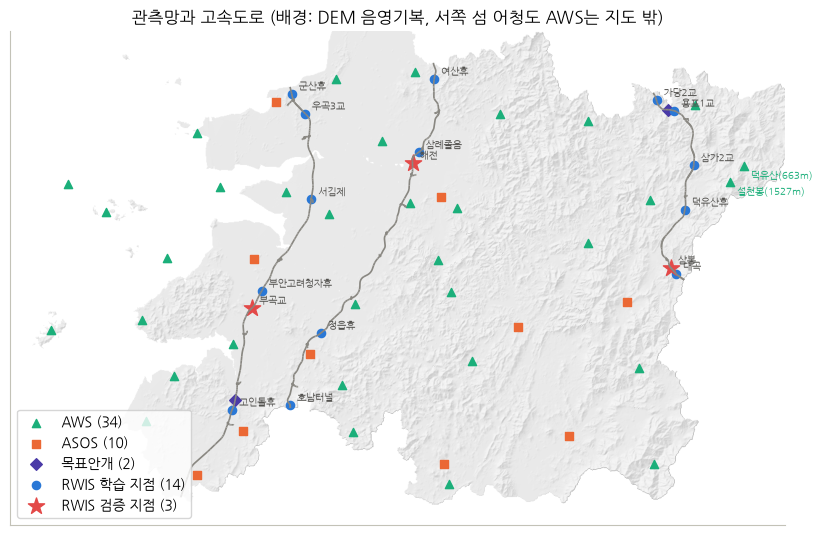

In [16]:
gy, gx = np.gradient(np.nan_to_num(dem_m, nan=0.0), 30 * step)
slope, aspect = np.arctan(np.hypot(gx, gy)), np.arctan2(-gx, gy)
hillshade = np.sin(np.radians(45)) * np.cos(slope) + np.cos(np.radians(45)) * np.sin(slope) * np.cos(np.radians(315) - aspect)
hillshade[np.isnan(dem_m)] = np.nan
DEM_EXTENT = [dem_bounds.left, dem_bounds.right, dem_bounds.bottom, dem_bounds.top]
centerline = gpd.read_file(config.RAW_DIR / config.RAW_FILES["centerline"])


def base_map(ax):
    ax.imshow(hillshade, extent=DEM_EXTENT, cmap="Greys_r", vmin=-0.2, vmax=1.2, alpha=0.35)
    centerline.plot(ax=ax, color=MUTED, linewidth=1.2)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])


fig, ax = plt.subplots(figsize=(10, 9))
base_map(ax)
aws_pt.plot(ax=ax, marker="^", color=PALETTE[2], markersize=35, label="AWS (34)")
asos_pt.plot(ax=ax, marker="s", color=PALETTE[1], markersize=40, label="ASOS (10)")
fog_pt.plot(ax=ax, marker="D", color=PALETTE[6], markersize=35, label="목표안개 (2)")
rwis_pt[~rwis_pt["검증지점"]].plot(ax=ax, color=PALETTE[0], markersize=35, label="RWIS 학습 지점 (14)")
rwis_pt[rwis_pt["검증지점"]].plot(ax=ax, color=PALETTE[7], marker="*", markersize=150, label="RWIS 검증 지점 (3)")
for _, r in rwis_pt.iterrows():
    ax.annotate(r["지점명"].replace("(도)", ""), (r.geometry.x, r.geometry.y), xytext=(5, 3),
                textcoords="offset points", fontsize=7.5, color="#52514e")
for _, r in aws_pt[aws_pt["stn"].isin([314, 735])].iterrows():
    ax.annotate(f"{r['지점명']}({r['DEM표고']:.0f}m)", (r.geometry.x, r.geometry.y), xytext=(5, -9),
                textcoords="offset points", fontsize=7.5, color=PALETTE[2])
view = pd.concat([d.geometry for d in (rwis_pt, asos_pt, fog_pt, aws_pt[aws_pt["stn"] != 700])])
ax.set_xlim(view.x.min() - 8000, view.x.max() + 8000)
ax.set_ylim(view.y.min() - 8000, view.y.max() + 8000)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("관측망과 고속도로 (배경: DEM 음영기복, 서쪽 섬 어청도 AWS는 지도 밖)")
ax.legend(loc="lower left")
plt.show()

### 2-4. 지점 간 거리

미관측 구간의 값을 주변 관측으로 추정하려면 "가까운 관측소가 얼마나 가까운가"가 중요하다.

In [17]:
xy = lambda g: np.c_[g.geometry.x, g.geometry.y]
train_pt = rwis_pt[~rwis_pt["검증지점"]]
D_rr = cdist(xy(rwis_pt), xy(train_pt)) / 1000
D_rr[D_rr == 0] = np.inf  # 자기 자신 제외
D_ra = cdist(xy(rwis_pt), xy(aws_pt)) / 1000
D_rs = cdist(xy(rwis_pt), xy(asos_pt)) / 1000
nearest = pd.DataFrame({
    "지점명": rwis_pt["지점명"].values, "노선": rwis_pt["노선"].values,
    "최근접 학습RWIS": train_pt["지점명"].values[D_rr.argmin(1)], "거리_RWIS(km)": D_rr.min(1),
    "최근접 AWS": aws_pt["지점명"].values[D_ra.argmin(1)], "거리_AWS(km)": D_ra.min(1),
    "AWS 표고차(m)": aws_pt["DEM표고"].values[D_ra.argmin(1)] - rwis_pt["DEM표고"].values,
    "최근접 ASOS": asos_pt["지점명"].values[D_rs.argmin(1)], "거리_ASOS(km)": D_rs.min(1),
}, index=rwis_pt["stn"].values)
nearest.round(1)

,지점명,노선,최근접 학습RWIS,거리_RWIS(km),최근접 AWS,거리_AWS(km),AWS 표고차(m),최근접 ASOS,거리_ASOS(km)
12103,군산휴(도),서해안,우곡3교(도),4.7,함라,9.1,18.1,군산,3.5
12209,서김제(도),서해안,우곡3교(도),16.8,김제,4.4,19.2,부안,16.1
12210,부안고려청자휴(도),서해안,정읍휴(도),14.2,줄포,11.8,0.0,부안,6.4
12211,고인돌휴(도),서해안,호남터널(도),11.3,줄포,12.8,-40.3,고창군,4.7
12409,우곡3교(도),서해안,군산휴(도),4.7,함라,9.0,20.2,군산,6.1
12410,부곡교(도),서해안,부안고려청자휴(도),3.8,줄포,8.0,0.0,부안,9.6
23202,여산휴(도),호남선,삼례졸음(도),14.6,여산,4.0,-21.2,전주,23.0
23203,삼례졸음(도),호남선,여산휴(도),14.6,익산,7.4,0.0,전주,9.6
23204,정읍휴(도),호남선,부안고려청자휴(도),14.2,태인,8.6,0.0,정읍,4.6
23402,해전(도),호남선,삼례졸음(도),2.4,익산,7.3,0.0,전주,8.6


- 학습 지점에서 가장 가까운 다른 학습 지점까지는 4~17km이다. 반면 **검증 지점 3곳은 1.6~3.8km 안에 학습 지점이 있다** (10장).
- 삼가2교의 최근접 AWS는 설천봉(해발 약 1,500m)으로, 관측소와 표고가 1,100m 넘게 차이 난다. 최근접 AWS를 그대로 쓰면 안 되는 사례이다.
- ASOS는 10개소뿐이라 RWIS에서 평균 15km 떨어져 있고, 통영-대전중부선 북부(용포1교·가당2교)는 40km 가까이 떨어져 있다.

고속도로 전체(본선 100m 간격 지점)에서 가장 가까운 학습 RWIS·AWS까지 거리를 보면, 미관측 구간이 관측소와 얼마나 떨어져 있는지 알 수 있다.

In [18]:
ROUTE_NAMES = {"서해안고속국도": "서해안", "통영-대전고속국도": "통영-대전중부선", "호남고속국도": "호남선"}
main = centerline[(centerline["ONSD"] == "ITH002") | (centerline["RDLN"] >= 2)]
samples = []
for name, g in main.groupby("NAME"):
    merged = shapely.line_merge(shapely.union_all(g.geometry.to_numpy()))
    for part in getattr(merged, "geoms", [merged]):
        if part.length < 300:
            continue
        for d in np.arange(0, part.length, 100):
            p = part.interpolate(d)
            samples.append((ROUTE_NAMES[name], p.x, p.y))
route_pts = gpd.GeoDataFrame(pd.DataFrame(samples, columns=["노선", "x", "y"]),
                             geometry=gpd.points_from_xy([s[1] for s in samples], [s[2] for s in samples]), crs=CRS)
route_pts["표고"] = sample_dem(route_pts)
route_pts["거리_학습RWIS"] = cdist(xy(route_pts), xy(train_pt)).min(1) / 1000
route_pts["거리_AWS"] = cdist(xy(route_pts), xy(aws_pt)).min(1) / 1000
dist_tbl = route_pts.groupby("노선")[["거리_학습RWIS", "거리_AWS"]].describe(percentiles=[0.5, 0.9])
dist_tbl.loc[:, (slice(None), ["mean", "50%", "90%", "max"])].round(1)

거리_학습RWIS                  거리_AWS                 
              mean  50%   90%   max   mean  50%   90%   max
노선                                                         
서해안            5.7  5.0  11.2  19.7    9.5  9.3  14.4  16.2
통영-대전중부선       2.8  2.4   5.8   7.2    8.3  7.7  14.3  16.9
호남선            6.8  5.4  16.0  17.4    6.8  7.2  10.3  11.1

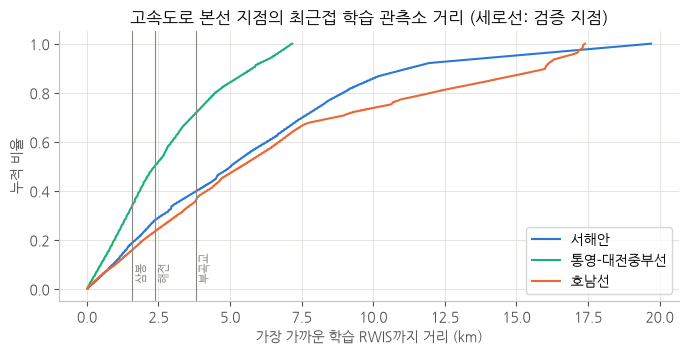

부곡교(도): 최근접 학습 지점 3.8km → 고속도로 지점 중 46%가 이보다 가깝다
삼봉(도): 최근접 학습 지점 1.6km → 고속도로 지점 중 22%가 이보다 가깝다
해전(도): 최근접 학습 지점 2.4km → 고속도로 지점 중 32%가 이보다 가깝다


In [19]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for route, g in route_pts.groupby("노선"):
    x = np.sort(g["거리_학습RWIS"])
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=ROUTE_COLORS[route], label=route)
for stn in HOLDOUT:
    d = nearest.loc[stn, "거리_RWIS(km)"]
    ax.axvline(d, color=MUTED, linewidth=0.8)
    ax.annotate(nearest.loc[stn, "지점명"].replace("(도)", ""), (d, 0.03), rotation=90, fontsize=8, color=MUTED,
                xytext=(2, 0), textcoords="offset points")
ax.set_xlabel("가장 가까운 학습 RWIS까지 거리 (km)")
ax.set_ylabel("누적 비율")
ax.set_title("고속도로 본선 지점의 최근접 학습 관측소 거리 (세로선: 검증 지점)")
ax.legend()
plt.show()
for stn in HOLDOUT:
    d = nearest.loc[stn, "거리_RWIS(km)"]
    print(f"{nearest.loc[stn, '지점명']}: 최근접 학습 지점 {d:.1f}km → 고속도로 지점 중 {(route_pts['거리_학습RWIS'] < d).mean():.0%}가 이보다 가깝다")

- 고속도로 본선의 절반은 학습 RWIS에서 약 4km 안에 있지만, 서해안·호남선에는 10~20km 떨어진 구간도 있다.
- 검증 지점의 최근접 거리(1.6~3.8km)는 고속도로 전체로 보면 하위 20~50% 수준이다. 검증 지점 성능이 먼 구간의 성능보다 좋게 나올 수 있다는 점을 염두에 둔다.

### 2-5. 노선 표고 단면

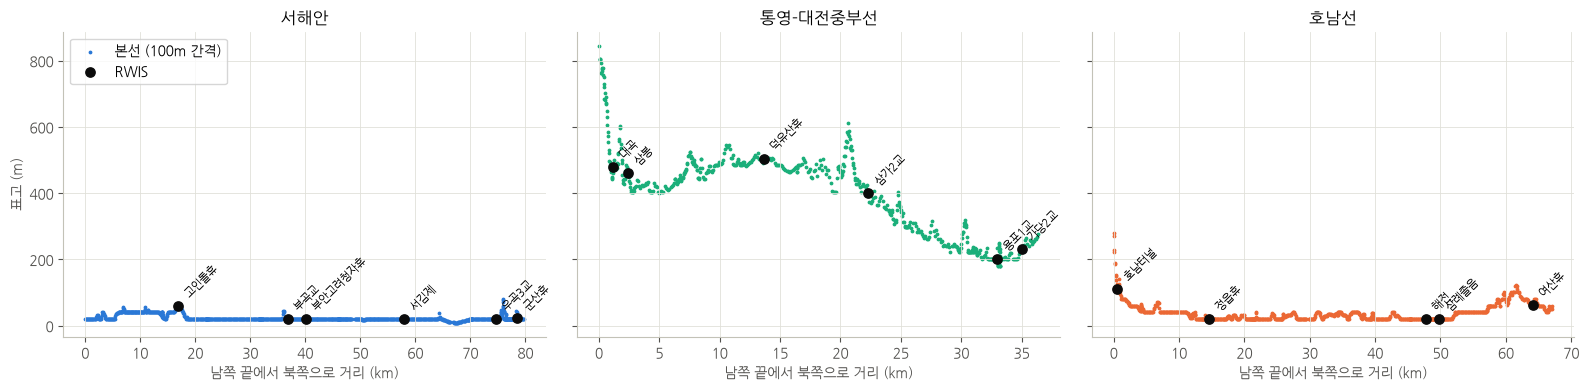

,count,mean,std,min,10%,50%,90%,max
노선,,,,,,,,
서해안,996.0,24.0,10.0,8.0,20.0,20.0,40.0,80.0
통영-대전중부선,587.0,400.0,133.0,181.0,219.0,431.0,522.0,846.0
호남선,860.0,39.0,28.0,20.0,20.0,31.0,70.0,279.0


In [20]:
route_pts["북쪽거리"] = (route_pts["y"] - route_pts.groupby("노선")["y"].transform("min")) / 1000
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, route in zip(axes, config.TARGET_ROUTES):
    g = route_pts[route_pts["노선"] == route].sort_values("북쪽거리")
    ax.scatter(g["북쪽거리"], g["표고"], s=3, color=ROUTE_COLORS[route], label="본선 (100m 간격)")
    y0 = route_pts.loc[route_pts["노선"] == route, "y"].min()
    s = rwis_pt[rwis_pt["노선"] == route]
    ax.scatter((s.geometry.y - y0) / 1000, s["DEM표고"], s=45, color=INK, zorder=5, label="RWIS")
    for _, r in s.iterrows():
        ax.annotate(r["지점명"].replace("(도)", ""), ((r.geometry.y - y0) / 1000, r["DEM표고"]), xytext=(3, 6),
                    textcoords="offset points", fontsize=8, rotation=45)
    ax.set_title(route)
    ax.set_xlabel("남쪽 끝에서 북쪽으로 거리 (km)")
axes[0].set_ylabel("표고 (m)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()
route_pts.groupby("노선")["표고"].describe(percentiles=[0.1, 0.5, 0.9]).round(0)

- 서해안선은 거의 해발 20~40m 평지, 호남선은 남쪽 끝(호남터널 부근)만 100m를 넘는다.
- 통영-대전중부선은 해발 180~850m의 산지 노선이다. 관측소(198~506m)는 노선 표고의 중간 범위에 있고,
  500m가 넘는 높은 구간은 관측소가 없다. 다만 표고 단면은 DEM 지표면이라 터널 구간에서는 터널 위 산의 높이가 잡힌다 (11장).

## 3. 자료 품질

### 3-1. 시간 축: 중복, 누락, 일별 완전성

In [21]:
print("RWIS 중복 행:", rwis.duplicated(["stn", "time"]).sum(), "/ AWS 중복 행:", aws.duplicated(["stn", "time"]).sum(),
      "/ ASOS 중복 행:", asos.duplicated(["stn", "time"]).sum())
print("10분 단위가 아닌 시각: RWIS", (rwis["time"].dt.minute % 10 != 0).sum(), "/ AWS", (aws["time"].dt.minute % 10 != 0).sum())
missing_times = 240 * 144 - rwis.groupby("stn")["time"].nunique()
print("RWIS 지점별 누락 시각 수:", missing_times[missing_times > 0].to_dict())
print("AWS 서전주(341) 관측 기간:", aws.loc[aws["stn"] == 341, "time"].min(), "~", aws.loc[aws["stn"] == 341, "time"].max())

RWIS 중복 행: 0 / AWS 중복 행: 0 / ASOS 중복 행: 0
10분 단위가 아닌 시각: RWIS 0 / AWS 0
RWIS 지점별 누락 시각 수: {12103: 6, 12209: 1, 12210: 1, 12211: 1, 12409: 14, 12410: 1, 23202: 37, 23203: 1, 23204: 5, 23402: 1, 23403: 1, 33103: 1, 33206: 1, 33409: 1, 33410: 1, 33411: 1, 33412: 1}
AWS 서전주(341) 관측 기간: 2025-12-10 00:00:00 ~ 2026-02-28 23:50:00


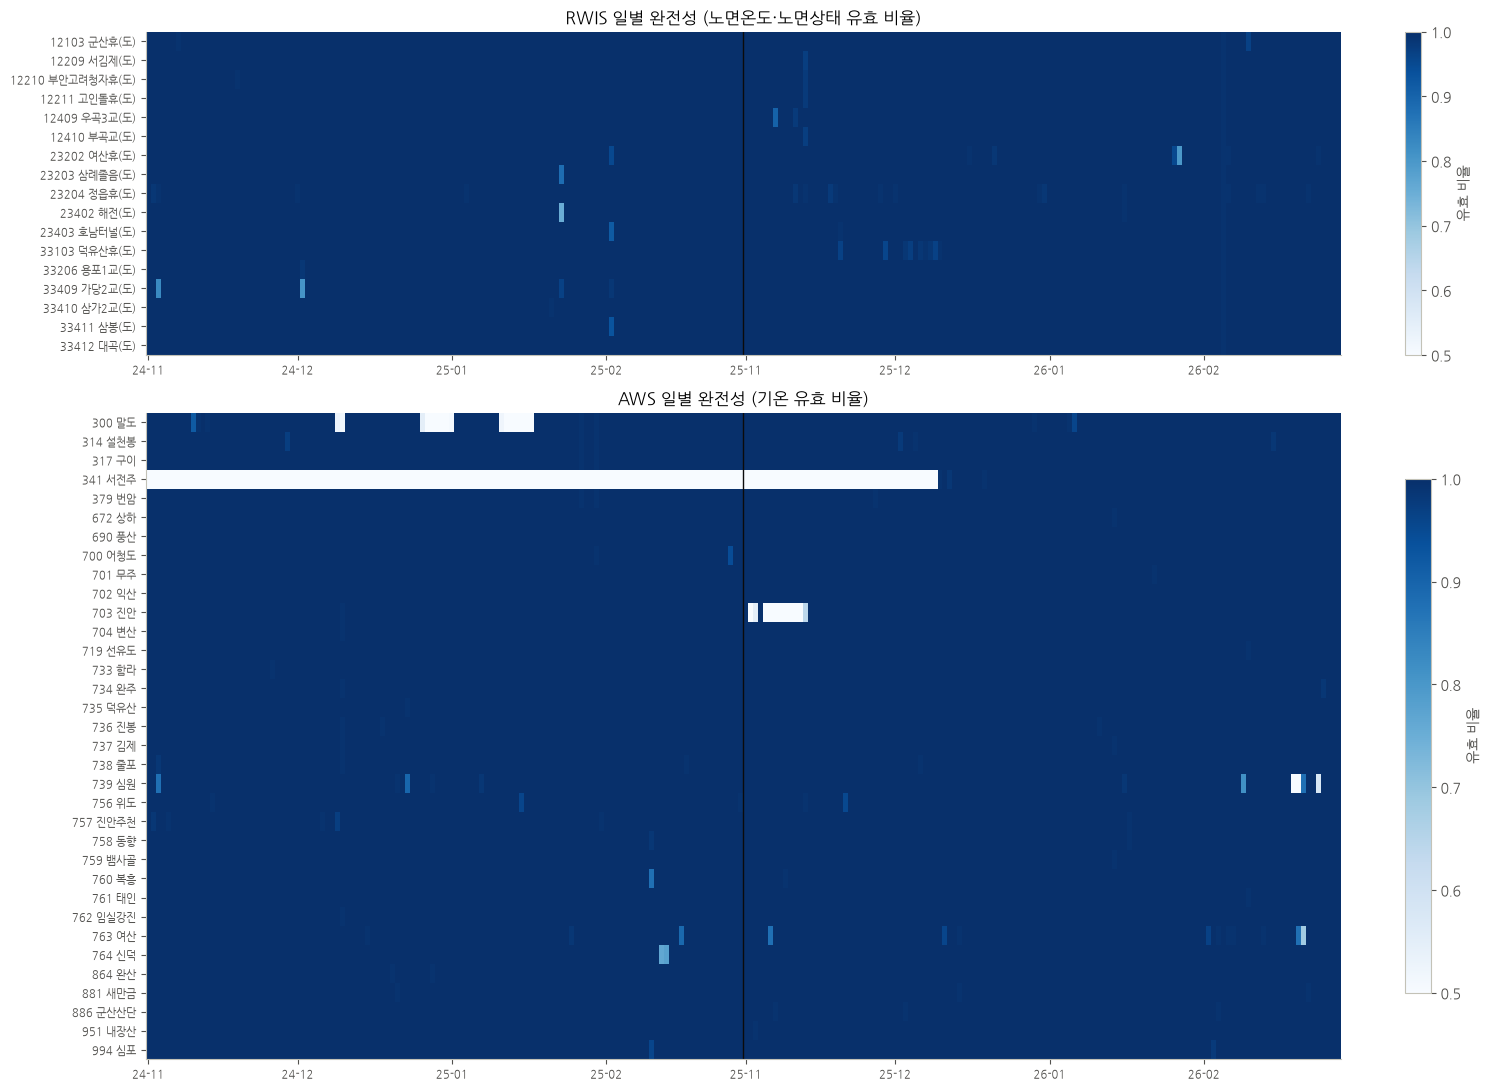

RWIS 지점-일 중 유효 90% 미만: 5 / 4080
AWS  지점-일 중 유효 90% 미만: 200 / 8160 (서전주 미설치 기간 제외 시 41 )


In [22]:
DAYS = pd.DatetimeIndex(sorted(rwis["time"].dt.normalize().unique()))


def completeness(df, ok_mask, stations):
    c = ok_mask.groupby([df["stn"], df["time"].dt.normalize()]).sum().unstack().reindex(index=stations, columns=DAYS)
    return (c.fillna(0) / 144)


def plot_day_heatmap(mat, labels, title, ax, cmap="Blues", vmin=0, vmax=1, cbar_label=""):
    im = ax.imshow(mat, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    month_start = [i for i, d in enumerate(DAYS) if d.day == 1]
    ax.set_xticks(month_start, [DAYS[i].strftime("%y-%m") for i in month_start], fontsize=8)
    ax.axvline(119.5, color=INK, linewidth=1)
    ax.grid(False)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label=cbar_label, fraction=0.02)


rwis_ok = (rwis["노면온도 (광학)"] > -999) & (rwis["노면상태"] > 0)
aws_ok = aws["1분 평균 기온(°C)"] > -99
c_rwis = completeness(rwis, rwis_ok, rwis_st["stn"])
c_aws = completeness(aws, aws_ok, aws_st["stn"])
fig, axes = plt.subplots(2, 1, figsize=(15, 11), gridspec_kw={"height_ratios": [17, 34]})
plot_day_heatmap(c_rwis.values, [f"{s} {n}" for s, n in zip(rwis_st["stn"], rwis_st["지점명"])],
                 "RWIS 일별 완전성 (노면온도·노면상태 유효 비율)", axes[0], vmin=0.5, cbar_label="유효 비율")
plot_day_heatmap(c_aws.values, [f"{s} {n}" for s, n in zip(aws_st["stn"], aws_st["지점명"])],
                 "AWS 일별 완전성 (기온 유효 비율)", axes[1], vmin=0.5, cbar_label="유효 비율")
plt.tight_layout()
plt.show()
print("RWIS 지점-일 중 유효 90% 미만:", int((c_rwis < 0.9).values.sum()), "/", c_rwis.size)
print("AWS  지점-일 중 유효 90% 미만:", int((c_aws < 0.9).values.sum()), "/", c_aws.size,
      "(서전주 미설치 기간 제외 시", int((c_aws.drop(index=341) < 0.9).values.sum()), ")")

- RWIS는 거의 모든 지점-일이 완전하다. 장기 결측은 없지만, **값은 있는데 틀린 경우**(센서 고착, 3-4)가 있다.
- AWS는 서전주가 2025-12-10부터만 관측되고, 말도(섬)·진안 등 일부 지점에 며칠씩 결측이 있다.

### 3-2. 결측 코드와 변수별 결측

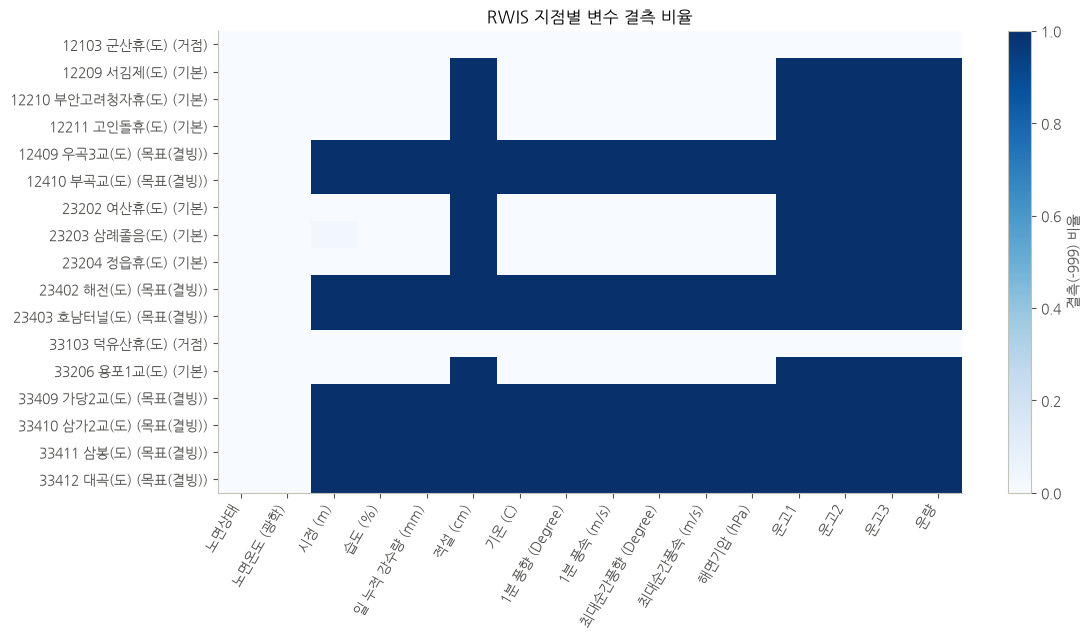

In [23]:
rwis_vars = ["노면상태", "노면온도 (광학)", "시정 (m)", "습도 (%)", "일 누적 강수량 (mm)", "적설 (cm)",
             "기온 (C)", "1분 풍향 (Degree)", "1분 풍속 (m/s)", "최대순간풍향 (Degree)",
             "최대순간풍속 (m/s)", "해면기압 (hPa)", "운고1", "운고2", "운고3", "운량"]
miss = (rwis[rwis_vars] == -999).groupby(rwis["stn"]).mean()

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(miss.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(rwis_vars)), rwis_vars, rotation=60, ha="right")
ax.set_yticks(range(len(miss)), [f"{s} {n} ({k})" for s, n, k in zip(rwis_st["stn"], rwis_st["지점명"], rwis_st["종류"])])
ax.grid(False)
fig.colorbar(im, ax=ax, label="결측(-999) 비율")
ax.set_title("RWIS 지점별 변수 결측 비율")
plt.show()

In [24]:
observed = {stn: ", ".join(v for v in rwis_vars if miss.loc[stn, v] < 0.5) for stn in miss.index}
rwis_st.assign(관측변수=rwis_st["stn"].map(observed)).groupby(["종류", "관측변수"])["지점명"].apply(", ".join).to_frame()

,,지점명
종류,관측변수,
거점,"노면상태, 노면온도 (광학), 시정 (m), 습도 (%), 일 누적 강수량 (mm), 적설 (cm), 기온 (C), 1분 풍향 (Degree), 1분 풍속 (m/s), 최대순간풍향 (Degree), 최대순간풍속 (m/s), 해면기압 (hPa), 운고1, 운고2, 운고3, 운량","군산휴(도), 덕유산휴(도)"
기본,"노면상태, 노면온도 (광학), 시정 (m), 습도 (%), 일 누적 강수량 (mm), 기온 (C), 1분 풍향 (Degree), 1분 풍속 (m/s), 최대순간풍향 (Degree), 최대순간풍속 (m/s), 해면기압 (hPa)","서김제(도), 부안고려청자휴(도), 고인돌휴(도), 여산휴(도), 삼례졸음(도), ..."
목표(결빙),"노면상태, 노면온도 (광학)","우곡3교(도), 부곡교(도), 해전(도), 호남터널(도), 가당2교(도), 삼가2교..."


- **목표(결빙) 관측소 8곳은 노면상태와 노면온도만 관측**한다. 검증 지점 3곳도 여기에 속하므로 검증 지점에서 비교할 수 있는 관측값은 노면온도(와 노면상태)뿐이다.
- 기본 관측소 7곳은 기온·습도·풍향풍속·강수·기압·시정을 함께 관측한다. 적설·운고·운량은 거점 2곳에만 있다.
- 결측은 관측소 종류(센서 구성)로 정해지고, 같은 종류 안에서는 결측이 거의 없다.

In [25]:
aws_vars = [c for c in aws.columns[5:21]]
aws_num = aws[aws_vars]
codes = aws_num[aws_num <= -99].stack().value_counts()
print("AWS -99 이하 값(결측 코드):", codes.to_dict())
aws_clean = aws_num.mask(aws_num <= -99)
pd.concat([(aws_num <= -99).mean().rename("결측 비율"), aws_clean.agg(["min", "max"]).T], axis=1).round(4)

AWS -99 이하 값(결측 코드): {-99.9: 183999, -99.7: 69186, -99.2: 32002, -99.5: 4503, -99.8: 225, -99.6: 3}


,결측 비율,min,max
1분 평균 풍향(degree),0.0061,0.0,360.0
1분 평균 풍속(m/s),0.0066,0.0,22.7
최대 순간 풍향(degree),0.0048,0.0,360.0
최대 순간 풍속(m/s),0.0040,0.0,31.4
10분 평균 풍향(degree),0.0076,0.0,360.0
10분 평균 풍속(m/s),0.0068,0.0,21.6
1분 평균 기온(°C),0.0033,-22.3,24.6
강수감지(0-무강수),0.0129,0.0,1.0
15분 누적 강수량(mm),0.0141,0.0,6.0
60분 누적 강수량(mm),0.0146,0.0,12.5


AWS 결측은 `-99.9`만이 아니라 `-99.2`, `-99.5`, `-99.7`, `-99.8` 등 여러 코드로 표기된다. 기온·이슬점도 -99°C 이하는 나올 수 없으므로
**-99 이하를 모두 결측**으로 본다. 현지·해면기압은 일부 지점(함라, 김제, 진안)에서 장기간 관측되지 않는다.

In [26]:
asos_vars = ["기온(°C)", "강수량(mm)", "풍속(m/s)", "습도(%)", "이슬점온도(°C)", "일조(hr)", "일사(MJ/m2)",
             "적설(cm)", "전운량(10분위)", "중하층운량(10분위)", "최저운고(100m)", "시정(10m)",
             "현상번호(국내식)", "지면온도(°C)", "5cm 지중온도(°C)"]
asos[asos_vars].isna().groupby(asos["지점명"]).mean().round(2)

,기온(°C),강수량(mm),풍속(m/s),습도(%),이슬점온도(°C),일조(hr),일사(MJ/m2),적설(cm),전운량(10분위),중하층운량(10분위),최저운고(100m),시정(10m),현상번호(국내식),지면온도(°C),5cm 지중온도(°C)
지점명,,,,,,,,,,,,,,,
고창,0.00,0.92,0.00,0.00,0.00,0.53,0.53,0.87,0.00,0.00,0.46,0.00,1.00,0.00,1.0
고창군,0.00,0.94,0.00,0.00,0.00,0.53,0.53,0.83,0.00,0.00,0.52,0.00,1.00,0.00,0.0
군산,0.01,0.95,0.01,0.01,0.01,0.53,1.00,0.91,0.00,0.01,0.49,0.01,1.00,0.02,1.0
남원,0.00,0.96,0.00,0.01,0.01,0.54,1.00,0.93,0.02,0.03,0.55,0.00,1.00,0.00,1.0
부안,0.00,0.94,0.00,0.00,0.00,0.53,1.00,0.86,0.00,0.00,0.55,0.00,1.00,0.02,1.0
순창군,0.00,0.95,0.00,0.00,0.00,0.53,0.53,0.86,0.00,0.00,0.60,0.00,1.00,0.01,0.0
임실,0.00,0.95,0.00,0.00,0.00,0.53,1.00,0.83,0.00,0.00,0.55,0.01,1.00,0.00,1.0
장수,0.00,0.96,0.00,0.00,0.00,0.53,1.00,0.82,0.00,0.00,0.59,0.01,1.00,0.00,1.0
전주,0.00,0.94,0.00,0.00,0.00,0.53,0.53,0.91,0.00,0.00,0.52,0.00,0.75,0.00,1.0


- ASOS의 기온·습도·이슬점·전운량·지면온도는 결측이 거의 없다.
- 강수량·적설·일조·현상번호는 현상이 없을 때 빈칸이다 (적설은 눈이 쌓였을 때만 기록). 일사는 5개소에만 일사계가 있다.

### 3-3. 값의 범위와 물리적 일관성

In [27]:
rwis_num = rwis[rwis_vars[1:]].mask(rwis[rwis_vars[1:]] == -999)
rwis_num.describe(percentiles=[0.001, 0.5, 0.999]).T.round(2)

,count,mean,std,min,0.1%,50%,99.9%,max
노면온도 (광학),587417.0,4.34,6.75,-13.3,-10.70,3.6,26.50,33.1
시정 (m),309789.0,23526.08,13862.00,10.0,100.00,22560.0,50000.00,50000.0
습도 (%),310986.0,71.33,18.86,6.9,14.40,73.6,100.00,100.0
일 누적 강수량 (mm),310986.0,0.29,1.33,0.0,0.00,0.0,16.00,22.0
적설 (cm),69113.0,2.55,8.48,0.0,0.00,0.0,33.80,34.4
기온 (C),310986.0,2.98,6.29,-17.4,-13.20,2.4,22.50,24.4
1분 풍향 (Degree),310916.0,178.48,99.72,0.0,0.00,200.7,359.50,360.0
1분 풍속 (m/s),310916.0,1.34,2.00,0.0,0.00,1.1,6.61,100.0
최대순간풍향 (Degree),310916.0,197.62,101.09,0.0,0.00,228.0,358.00,359.9
최대순간풍속 (m/s),310916.0,2.45,2.32,0.0,0.00,2.2,10.40,100.0


In [28]:
print("RWIS 1분 풍속 100 m/s 이상:", (rwis["1분 풍속 (m/s)"] >= 100).sum(), "행 / 최대순간풍속 100 m/s 이상:",
      (rwis["최대순간풍속 (m/s)"] >= 100).sum(), "행")
print("RWIS 시정 50,000m(상한값):", (rwis["시정 (m)"] == 50000).sum(), "행")
ta, td, rh = aws_clean["1분 평균 기온(°C)"], aws_clean["이슬점온도(°C)"], aws_clean["1분 평균 상대습도(%)"]
gamma = np.log(rh / 100) + 17.62 * ta / (243.12 + ta)
td_magnus = 243.12 * gamma / (17.62 - gamma)
print(f"AWS 이슬점 > 기온+0.5°C: {(td > ta + 0.5).sum()}건, 기온·습도로 계산한 이슬점과의 평균 차이 {np.nanmean(np.abs(td_magnus - td)):.3f}°C")
low_p = aws_clean["1분 평균 현지기압(hPa)"] < 900
print("AWS 현지기압 900hPa 미만:", aws.loc[low_p, "지점명"].value_counts().to_dict())

RWIS 1분 풍속 100 m/s 이상: 98 행 / 최대순간풍속 100 m/s 이상: 99 행
RWIS 시정 50,000m(상한값): 1383 행
AWS 이슬점 > 기온+0.5°C: 0건, 기온·습도로 계산한 이슬점과의 평균 차이 0.026°C
AWS 현지기압 900hPa 미만: {'설천봉': 34552, '위도': 1}


- RWIS 풍속 100 m/s(98건)는 물리적으로 불가능한 값이라 결측으로 처리한다. 시정은 50,000m가 상한이다.
- AWS 이슬점은 기온·습도와 Magnus 식으로 정확히 맞는다(평균 차이 0.03°C). 이슬점이 기온보다 높은 오류도 없다.
- 현지기압 900hPa 미만은 대부분 설천봉(해발 약 1,500m, 정상값 850hPa 안팎)이고, 위도 1건(10hPa)만 이상값이다.

### 3-4. 센서 고착(같은 값이 오래 이어지는 현상)

기상 값은 10분마다 조금씩 변하므로, 같은 값이 몇 시간 이상 이어지면 센서가 멈춘 것으로 의심할 수 있다.

In [29]:
def longest_runs(df, col, missing, min_steps):
    """지점별로 같은 값이 min_steps 이상 이어진 구간."""
    out = []
    for stn, g in df.sort_values(["stn", "time"]).groupby("stn"):
        x = g[col].to_numpy(dtype=float)
        x = np.where(x <= missing, np.nan, x)
        same = np.r_[False, (x[1:] == x[:-1]) & ~np.isnan(x[1:])]
        grp = np.cumsum(~same)
        runs = pd.DataFrame({"t": g["time"].to_numpy(), "v": x, "grp": grp}).groupby("grp").agg(
            시작=("t", "first"), 끝=("t", "last"), n=("t", "size"), 값=("v", "first"))
        for _, r in runs[runs["n"] >= min_steps].iterrows():
            out.append({"stn": stn, "변수": col, "시작": r["시작"], "끝": r["끝"], "지속(시간)": r["n"] / 6, "값": r["값"]})
    return pd.DataFrame(out)


stuck = pd.concat([longest_runs(rwis, c, -999, 36) for c in ["노면온도 (광학)", "기온 (C)", "습도 (%)"]]
                  + [longest_runs(aws, c, -99, 36) for c in ["1분 평균 기온(°C)"]], ignore_index=True)
stuck.sort_values("지속(시간)", ascending=False).head(12).round(1)

,stn,변수,시작,끝,지속(시간),값
0,23202,노면온도 (광학),2025-11-19 10:30:00,2025-12-16 11:50:00,649.5,10.7
24,12211,습도 (%),2025-12-13 11:50:00,2025-12-14 11:50:00,24.2,100.0
16,12211,습도 (%),2024-11-01 09:10:00,2024-11-02 08:30:00,23.5,100.0
27,12211,습도 (%),2026-02-10 12:30:00,2026-02-11 11:20:00,23.0,100.0
15,12210,습도 (%),2026-02-10 13:20:00,2026-02-11 11:50:00,22.7,100.0
54,33206,습도 (%),2025-12-23 19:10:00,2025-12-24 14:30:00,19.5,100.0
28,12211,습도 (%),2026-02-24 15:50:00,2026-02-25 11:00:00,19.3,100.0
8,12210,습도 (%),2025-01-31 21:30:00,2025-02-01 15:30:00,18.2,100.0
4,12210,습도 (%),2024-11-28 22:20:00,2024-11-29 16:10:00,18.0,100.0
26,12211,습도 (%),2025-12-23 17:50:00,2025-12-24 09:20:00,15.7,100.0


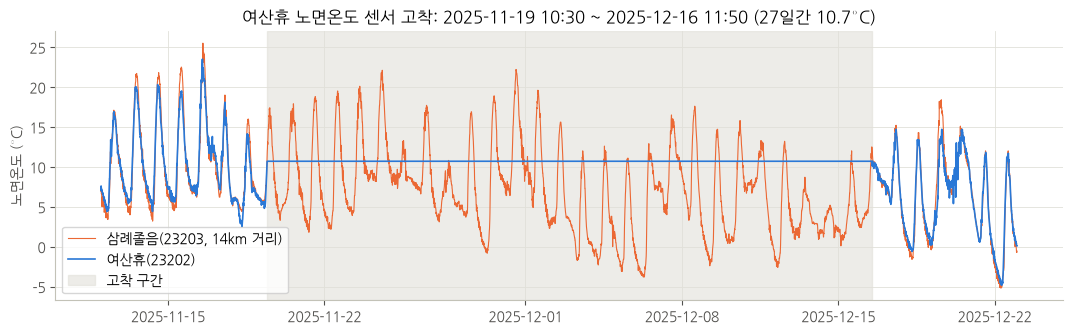

고착 구간의 노면상태: {1: 3897}


In [30]:
STUCK = stuck[stuck["변수"] == "노면온도 (광학)"].sort_values("지속(시간)").iloc[-1]
w = rwis[rwis["stn"].isin([23202, 23203])].pivot(index="time", columns="stn", values="노면온도 (광학)")
w = w.loc["2025-11-12":"2025-12-22"]
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(w.index, w[23203], color=PALETTE[1], linewidth=0.8, label="삼례졸음(23203, 14km 거리)")
ax.plot(w.index, w[23202], color=PALETTE[0], linewidth=1.2, label="여산휴(23202)")
ax.axvspan(STUCK["시작"], STUCK["끝"], color="#e1e0d9", alpha=0.6, label="고착 구간")
ax.set_ylabel("노면온도 (°C)")
ax.set_title(f"여산휴 노면온도 센서 고착: {STUCK['시작']:%Y-%m-%d %H:%M} ~ {STUCK['끝']:%Y-%m-%d %H:%M} "
             f"({STUCK['지속(시간)'] / 24:.0f}일간 {STUCK['값']}°C)")
ax.legend(loc="lower left")
plt.show()
in_stuck = (rwis["stn"] == 23202) & rwis["time"].between(STUCK["시작"], STUCK["끝"])
print("고착 구간의 노면상태:", rwis.loc[in_stuck, "노면상태"].value_counts().to_dict())

- **여산휴(23202)는 2025-11-19 ~ 12-16, 27일 동안 노면온도가 10.7°C, 노면상태가 Dry로 고정되어 있다.** 결측 코드가 아니어서
  결측 점검으로는 걸러지지 않는다. 같은 기간 이웃 관측소는 영하까지 내려가므로 센서 고장이 분명하다.
  이 구간은 노면온도·노면상태 모두 결측으로 처리해야 한다 (02-1에서 6시간 이상 같은 값 고착을 제거).
- 다른 지점·변수에는 이런 장기 고착이 없다. 습도 100%가 몇 시간 이어지는 것은 안개·강수 때의 포화로 볼 수 있다.

In [31]:
jumps = {}
for stn, g in rwis.sort_values(["stn", "time"]).groupby("stn"):
    x = g["노면온도 (광학)"].where(g["노면온도 (광학)"] > -999)
    d = x.diff().abs()
    jumps[stn] = {"3°C 초과 변화": int((d > 3).sum()), "5°C 초과 변화": int((d > 5).sum()), "최대 변화": d.max()}
pd.DataFrame(jumps).T.join(rwis_st.set_index("stn")["지점명"]).sort_values("3°C 초과 변화", ascending=False).head(8)

,3°C 초과 변화,5°C 초과 변화,최대 변화,지점명
12103,52.0,6.0,24.0,군산휴(도)
33410,41.0,2.0,7.2,삼가2교(도)
12409,34.0,3.0,10.2,우곡3교(도)
12410,28.0,6.0,14.9,부곡교(도)
12210,26.0,8.0,19.1,부안고려청자휴(도)
12211,21.0,3.0,8.8,고인돌휴(도)
33206,20.0,1.0,9.3,용포1교(도)
23202,15.0,2.0,11.6,여산휴(도)


10분 사이 노면온도가 5°C 넘게 변하는 경우는 지점당 1~8건으로 드물다. 대부분 맑은 날 오전에 햇빛이 들거나 그늘이 지는 순간이어서
이상값으로 보지 않는다.

### 3-5. 자료 간 시각 정렬

RWIS 기온과 가장 가까운 AWS 기온의 시차 상관을 보면, 두 자료의 시각 기준이 같은지(예: KST·UTC 혼동, 10분 밀림) 확인할 수 있다.
하루 평균을 뺀 편차로 비교해 일변화 패턴의 시점을 맞춰 본다.

In [32]:
aws_t = aws.assign(ta=aws_clean["1분 평균 기온(°C)"]).pivot(index="time", columns="stn", values="ta")
rows = []
for stn in rwis_st.loc[rwis_st["종류"] != "목표(결빙)", "stn"]:
    t_r = rwis.loc[rwis["stn"] == stn].set_index("time")["기온 (C)"]
    t_r = t_r.where(t_r > -999)
    nn = nearest.loc[stn, "최근접 AWS"]
    t_a = aws_t[aws_st.set_index("지점명").loc[nn, "stn"]].reindex(t_r.index)
    anom_r = t_r - t_r.groupby(t_r.index.date).transform("mean")
    anom_a = t_a - t_a.groupby(t_a.index.date).transform("mean")
    lag_corr = {lag * 10: anom_r.corr(anom_a.shift(lag)) for lag in range(-3, 4)}
    rows.append({"stn": stn, "지점명": nearest.loc[stn, "지점명"], "최근접 AWS": nn,
                 "거리(km)": nearest.loc[stn, "거리_AWS(km)"], "상관": t_r.corr(t_a),
                 "평균차(RWIS-AWS)": (t_r - t_a).mean(), "최대상관 시차(분)": max(lag_corr, key=lag_corr.get)})
pd.DataFrame(rows).set_index("stn").round(2)

,지점명,최근접 AWS,거리(km),상관,평균차(RWIS-AWS),최대상관 시차(분)
stn,,,,,,
12103,군산휴(도),함라,9.10,0.99,0.39,0
12209,서김제(도),김제,4.45,0.98,-0.50,0
12210,부안고려청자휴(도),줄포,11.76,0.99,0.23,0
12211,고인돌휴(도),줄포,12.78,0.99,0.28,0
23202,여산휴(도),여산,3.96,0.96,1.24,0
23203,삼례졸음(도),익산,7.41,0.94,0.35,0
23204,정읍휴(도),태인,8.60,0.95,0.76,0
33103,덕유산휴(도),동향,6.97,0.96,0.48,-10
33206,용포1교(도),무주,4.22,0.90,0.92,0


- 거의 모든 지점에서 시차 0분일 때 상관이 가장 높다. 세 자료 모두 KST 기준으로 시각이 맞는다.
- RWIS 기온은 대부분 가까운 AWS보다 평균 0.2~1.2°C 높다(서김제만 0.5°C 낮다). 고속도로 노면·차량 열, 관측 높이,
  주변 지형 차이 등의 영향으로 보인다. 보간 기온에는 이 정도의 계통 오차가 있을 수 있다.

### 3-6. 분석용 자료 저장

3장에서 확인한 내용을 반영해 01-3 ~ 01-7에서 함께 쓸 분석용 자료를 만든다.

- 노면온도·노면상태의 결측 코드(-999, 0)를 결측으로 바꾸고, 3-4의 센서 고착 구간(여산휴)도 결측으로 처리한다.
- 날짜·시·겨울·월, Ice 여부, 노선·관측소 종류 열을 붙인다.
- 관측 자료 4종, 지점 정보(DEM 표고 포함), DEM 환산 계수를 `config.INTERIM_DIR`(`data/interim/`)에 저장한다.

In [33]:
rwis["rst"] = rwis["노면온도 (광학)"].where(rwis["노면온도 (광학)"] > -999)
rwis["state"] = rwis["노면상태"].where(rwis["노면상태"] > 0)
rwis.loc[in_stuck, ["rst", "state"]] = np.nan
rwis["ta"] = rwis["기온 (C)"].where(rwis["기온 (C)"] > -999)
rwis["rh"] = rwis["습도 (%)"].where(rwis["습도 (%)"] > -999)
rwis["date"] = rwis["time"].dt.normalize()
rwis["hour"] = rwis["time"].dt.hour
rwis["winter"] = np.where(rwis["time"] < "2025-06-01", "2024-25", "2025-26")
rwis["ice"] = rwis["state"].isin(config.ICE_STATE_CODES).astype(int)
rwis["노선"], rwis["종류"] = rwis["고속도로"], rwis["관측소 종류"]
rwis["month"] = rwis["time"].dt.month

In [34]:
out = config.INTERIM_DIR
out.mkdir(parents=True, exist_ok=True)
for name, df in {"rwis": rwis, "fog": fog, "asos": asos, "aws": aws}.items():
    df.to_parquet(out / f"{name}.parquet", index=False)
for name, pt in {"rwis": rwis_pt, "asos": asos_pt, "aws": aws_pt}.items():  # 지점 정보 + DEM 표고
    pd.DataFrame(pt.drop(columns="geometry")).to_parquet(out / f"stations_{name}.parquet", index=False)
with open(out / "eda_meta.json", "w", encoding="utf-8") as f:
    json.dump({"dem_scale": float(dem_scale)}, f, ensure_ascii=False, indent=2)
for p in sorted(out.iterdir()):
    print(f"{p.name:24s} {p.stat().st_size / 1e6:7.1f} MB")

asos.parquet                 0.9 MB
aws.parquet                 16.6 MB
bridge_poly.gpkg             6.5 MB
eda_meta.json                0.0 MB
fog.parquet                  0.7 MB
hw_tunnels.gpkg              0.1 MB
lapse_rates.parquet          1.0 MB
rwis.parquet                 6.2 MB
rwis_pairs.parquet           0.0 MB
rwis_weather.parquet        14.2 MB
stations_asos.parquet        0.0 MB
stations_aws.parquet         0.0 MB
stations_rwis.parquet        0.0 MB
